In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
import os

# Tekrarlanabilirlik ayarları
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow sürümü:", tf.__version__)
print("NumPy sürümü:", np.__version__)
print("Rastgelelik tohumu:", SEED)

TensorFlow sürümü: 2.21.0
NumPy sürümü: 2.4.6
Rastgelelik tohumu: 42


In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
import os

# Tekrarlanabilirlik ayarları
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow sürümü:", tf.__version__)
print("NumPy sürümü:", np.__version__)
print("Rastgelelik tohumu:", SEED)

TensorFlow sürümü: 2.21.0
NumPy sürümü: 2.4.6
Rastgelelik tohumu: 42


In [ ]:
# Fashion-MNIST veri setini yükleme
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print("Eğitim görüntüleri:", x_train.shape)
print("Eğitim etiketleri:", y_train.shape)
print("Test görüntüleri:", x_test.shape)
print("Test etiketleri:", y_test.shape)

Eğitim görüntüleri: (60000, 28, 28)
Eğitim etiketleri: (60000,)
Test görüntüleri: (10000, 28, 28)
Test etiketleri: (10000,)


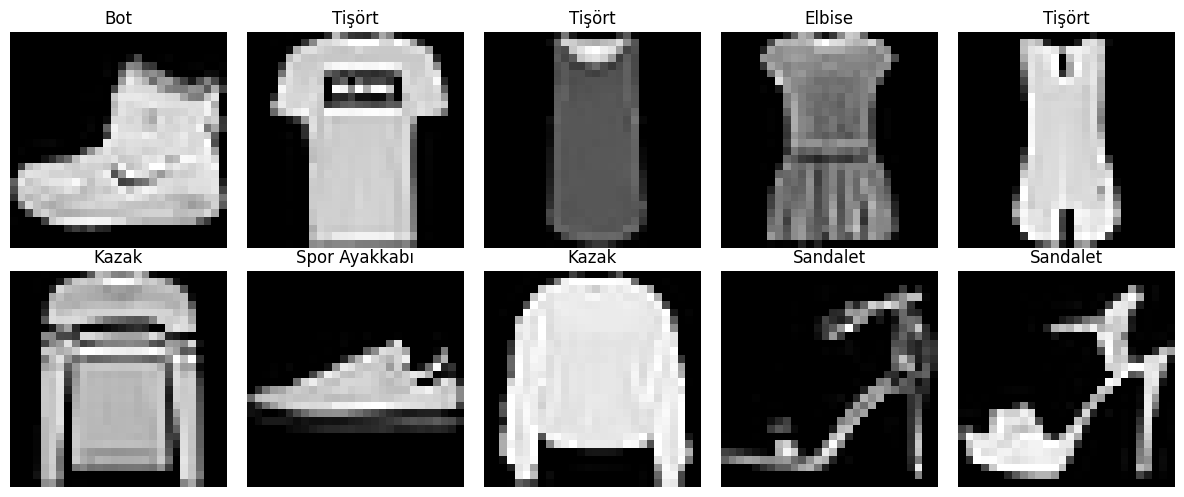

In [ ]:
# Sınıf isimleri
class_names = [
    "Tişört", "Pantolon", "Kazak", "Elbise", "Mont",
    "Sandalet", "Gömlek", "Spor Ayakkabı", "Çanta", "Bot"
]

# İlk 10 görüntüyü gösterme
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Görüntüleri 0-1 aralığına normalleştirme
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# CNN için kanal boyutu ekleme
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Eğitim verisinin yeni boyutu:", x_train.shape)
print("Test verisinin yeni boyutu:", x_test.shape)
print("Piksel değerlerinin minimumu:", x_train.min())
print("Piksel değerlerinin maksimumu:", x_train.max())

Eğitim verisinin yeni boyutu: (60000, 28, 28, 1)
Test verisinin yeni boyutu: (10000, 28, 28, 1)
Piksel değerlerinin minimumu: 0.0
Piksel değerlerinin maksimumu: 1.0


In [ ]:
# Sınıflara göre görüntü sayıları
class_counts = pd.Series(y_train).value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Sınıf": class_names,
    "Görüntü Sayısı": class_counts.values
})

display(class_distribution)

,Sınıf,Görüntü Sayısı
0,Tişört,6000
1,Pantolon,6000
2,Kazak,6000
3,Elbise,6000
4,Mont,6000
5,Sandalet,6000
6,Gömlek,6000
7,Spor Ayakkabı,6000
8,Çanta,6000
9,Bot,6000


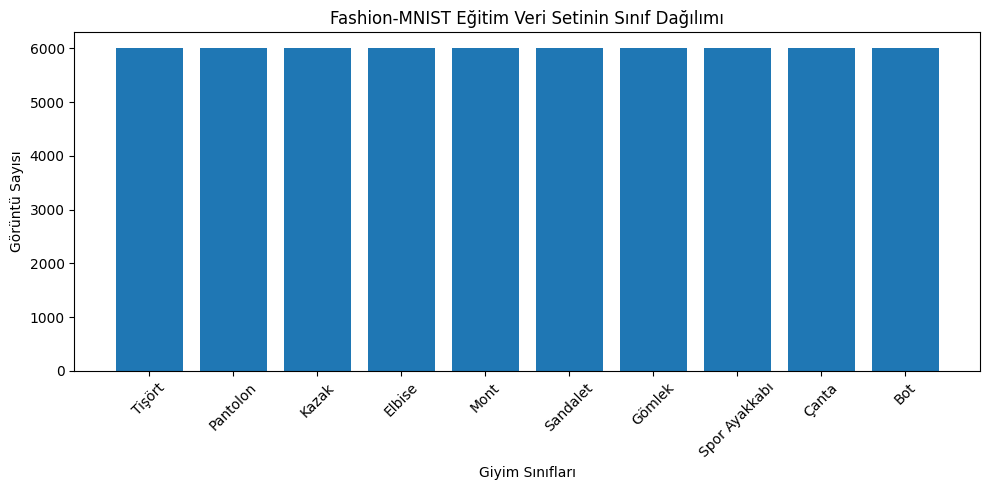

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(class_names, class_distribution["Görüntü Sayısı"])

plt.title("Fashion-MNIST Eğitim Veri Setinin Sınıf Dağılımı")
plt.xlabel("Giyim Sınıfları")
plt.ylabel("Görüntü Sayısı")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("sekil_1_sinif_dagilimi.png", dpi=300)
plt.show()

In [ ]:
# CNN modelinin oluşturulması

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1), name="giris"),

    tf.keras.layers.Conv2D(
        32, (3, 3), padding="same",
        activation="relu", name="conv1"
    ),

    tf.keras.layers.MaxPooling2D(name="pool1"),

    tf.keras.layers.Conv2D(
        64, (3, 3), padding="same",
        activation="relu", name="conv2"
    ),

    tf.keras.layers.MaxPooling2D(name="pool2"),

    tf.keras.layers.Conv2D(
        128, (3, 3), padding="same",
        activation="relu", name="conv3"
    ),

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dropout(0.30),

    tf.keras.layers.Dense(
        10, activation="softmax", name="cikis"
    )
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cikis (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,962 (367.04 KB)

 Trainable params: 93,962 (367.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model başarıyla derlendi.")

Model başarıyla derlendi.


In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train,
    test_size=0.10,
    random_state=42,
    stratify=y_train
)

print("Yeni eğitim veri boyutu:", x_train.shape)
print("Doğrulama veri boyutu:", x_val.shape)
print("Test veri boyutu:", x_test.shape)

Yeni eğitim veri boyutu: (54000, 28, 28, 1)
Doğrulama veri boyutu: (6000, 28, 28, 1)
Test veri boyutu: (10000, 28, 28, 1)


In [ ]:
EPOCHS = 10
BATCH_SIZE = 128

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 87s 204ms/step - accuracy: 0.6054 - loss: 1.0532 - val_accuracy: 0.7392 - val_loss: 0.6869
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 141s 202ms/step - accuracy: 0.7543 - loss: 0.6752 - val_accuracy: 0.7798 - val_loss: 0.5768
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 85s 202ms/step - accuracy: 0.7855 - loss: 0.5879 - val_accuracy: 0.8098 - val_loss: 0.5086
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 85s 203ms/step - accuracy: 0.8065 - loss: 0.5317 - val_accuracy: 0.8360 - val_loss: 0.4520
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 142s 202ms/step - accuracy: 0.8230 - loss: 0.4884 - val_accuracy: 0.8503 - val_loss: 0.4117
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 143s 204ms/step - accuracy: 0.8346 - loss: 0.4559 - val_accuracy: 0.8613 - val_loss: 0.3825
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 87s 207ms/step - accuracy: 0.8455 - loss: 0.4316 - val_accuracy: 0.8643 - val_loss: 0.3715
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 85s 203ms/step - accuracy: 0.8529 - loss

In [ ]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("Test doğruluğu: %", round(test_accuracy * 100, 2))
print("Test kaybı:", round(test_loss, 4))

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8669 - loss: 0.3624
Test doğruluğu: % 86.69
Test kaybı: 0.3624


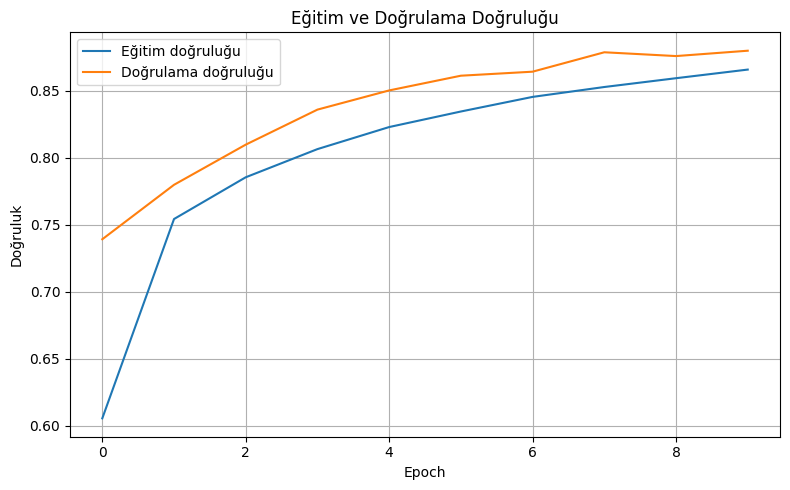

In [ ]:
# Eğitim ve doğrulama doğruluğu grafiği
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Eğitim doğruluğu")
plt.plot(history.history["val_accuracy"], label="Doğrulama doğruluğu")

plt.title("Eğitim ve Doğrulama Doğruluğu")
plt.xlabel("Epoch")
plt.ylabel("Doğruluk")
plt.legend()
plt.grid()
plt.tight_layout()

plt.savefig("sekil_2_dogruluk.png", dpi=300)
plt.show()

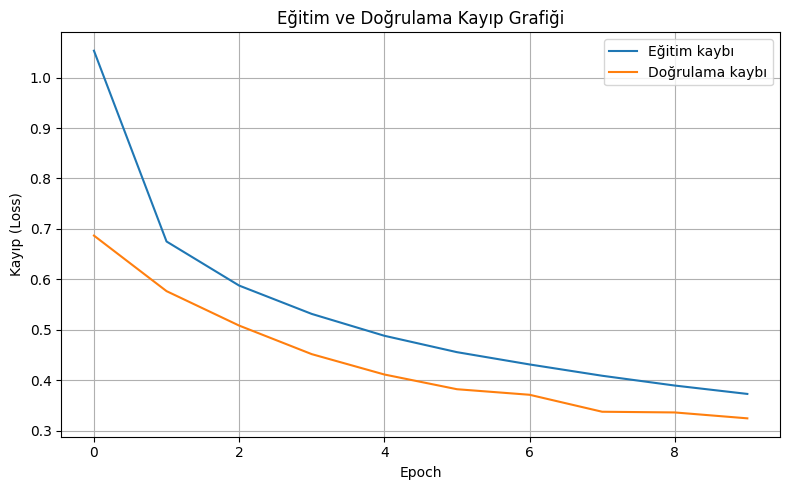

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Eğitim kaybı")
plt.plot(history.history["val_loss"], label="Doğrulama kaybı")

plt.title("Eğitim ve Doğrulama Kayıp Grafiği")
plt.xlabel("Epoch")
plt.ylabel("Kayıp (Loss)")
plt.legend()
plt.grid()
plt.tight_layout()

plt.savefig("sekil_3_kayip.png", dpi=300)
plt.show()

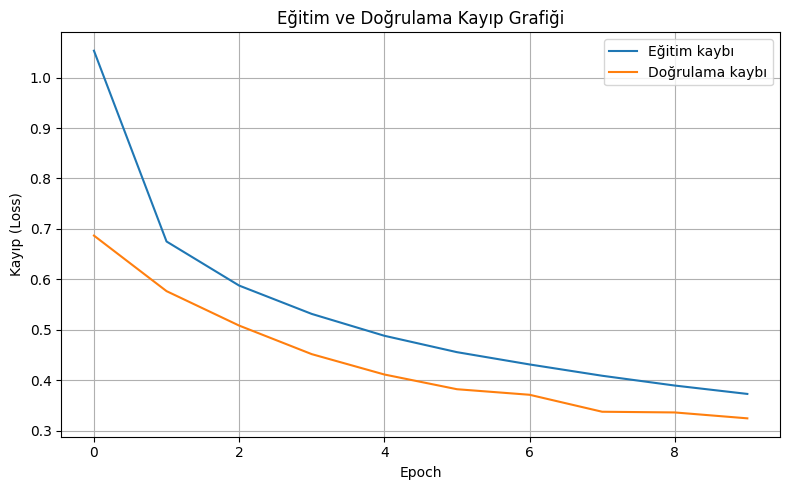

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Eğitim kaybı")
plt.plot(history.history["val_loss"], label="Doğrulama kaybı")

plt.title("Eğitim ve Doğrulama Kayıp Grafiği")
plt.xlabel("Epoch")
plt.ylabel("Kayıp (Loss)")
plt.legend()
plt.grid()
plt.tight_layout()

plt.savefig("sekil_3_kayip.png", dpi=300)
plt.show()

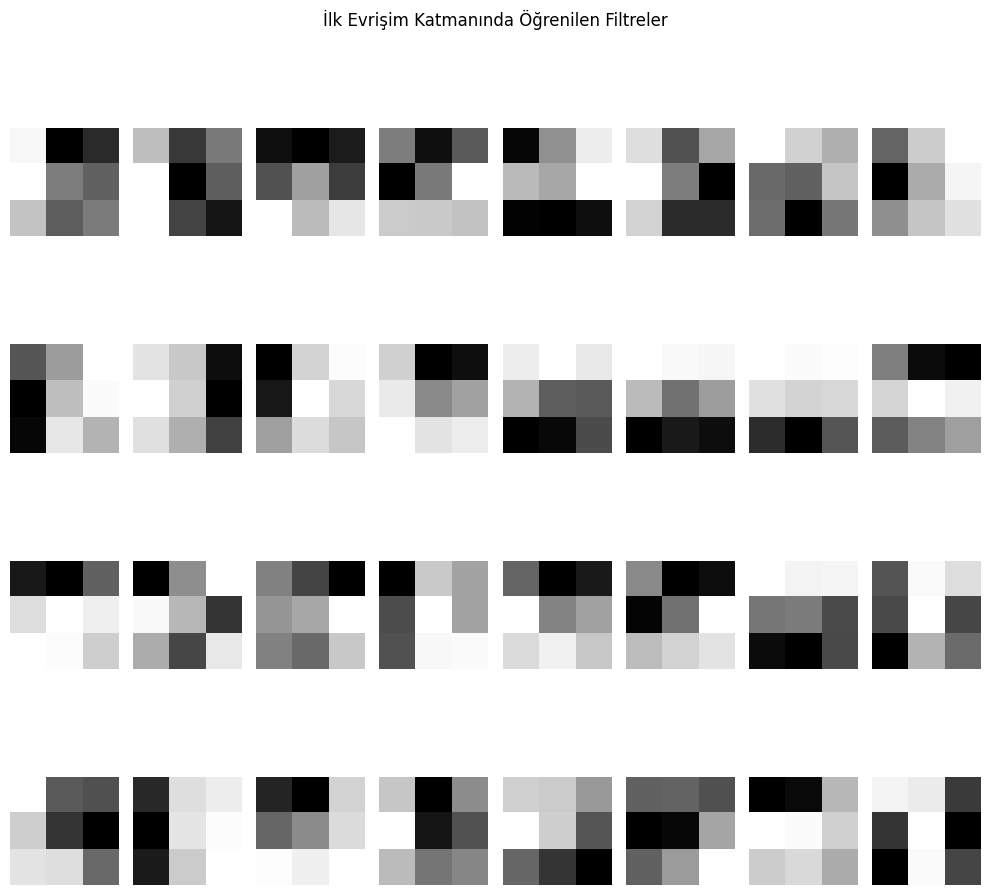

In [ ]:
# İlk evrişim katmanının filtrelerini al
filters, biases = model.get_layer("conv1").get_weights()

plt.figure(figsize=(10, 10))

for i in range(32):
    plt.subplot(4, 8, i + 1)
    plt.imshow(filters[:, :, 0, i], cmap="gray")
    plt.axis("off")

plt.suptitle("İlk Evrişim Katmanında Öğrenilen Filtreler")
plt.tight_layout()
plt.savefig("sekil_5_ogrenilen_filtreler.png", dpi=300)
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


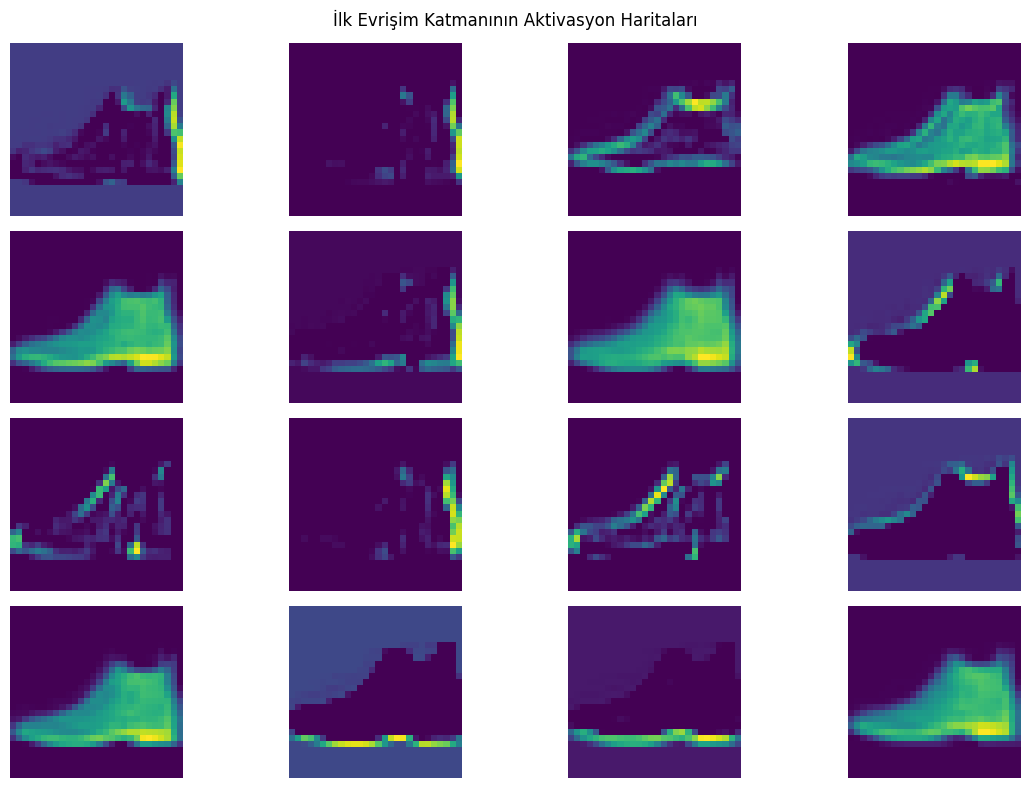

In [ ]:
# Modelin ilk evrişim katmanının çıktısını al
activation_model = tf.keras.Model(
    inputs=model.inputs[0],
    outputs=model.get_layer("conv1").output
)

# Test görüntüsünü modele ver
sample_image = x_test[0:1]
activations = activation_model.predict(sample_image)

# Aktivasyon haritalarını çiz
plt.figure(figsize=(12, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(activations[0, :, :, i], cmap="viridis")
    plt.axis("off")

plt.suptitle("İlk Evrişim Katmanının Aktivasyon Haritaları")
plt.tight_layout()
plt.savefig("sekil_6_aktivasyon_haritalari.png", dpi=300)
plt.show()

In [ ]:
y_pred_prob = model.predict(x_test)
y_pred = np.argmax(y_pred_prob, axis=1)

print("Tahminler yeniden oluşturuldu.")
print("Tahmin sayısı:", len(y_pred))

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step
Tahminler yeniden oluşturuldu.
Tahmin sayısı: 10000


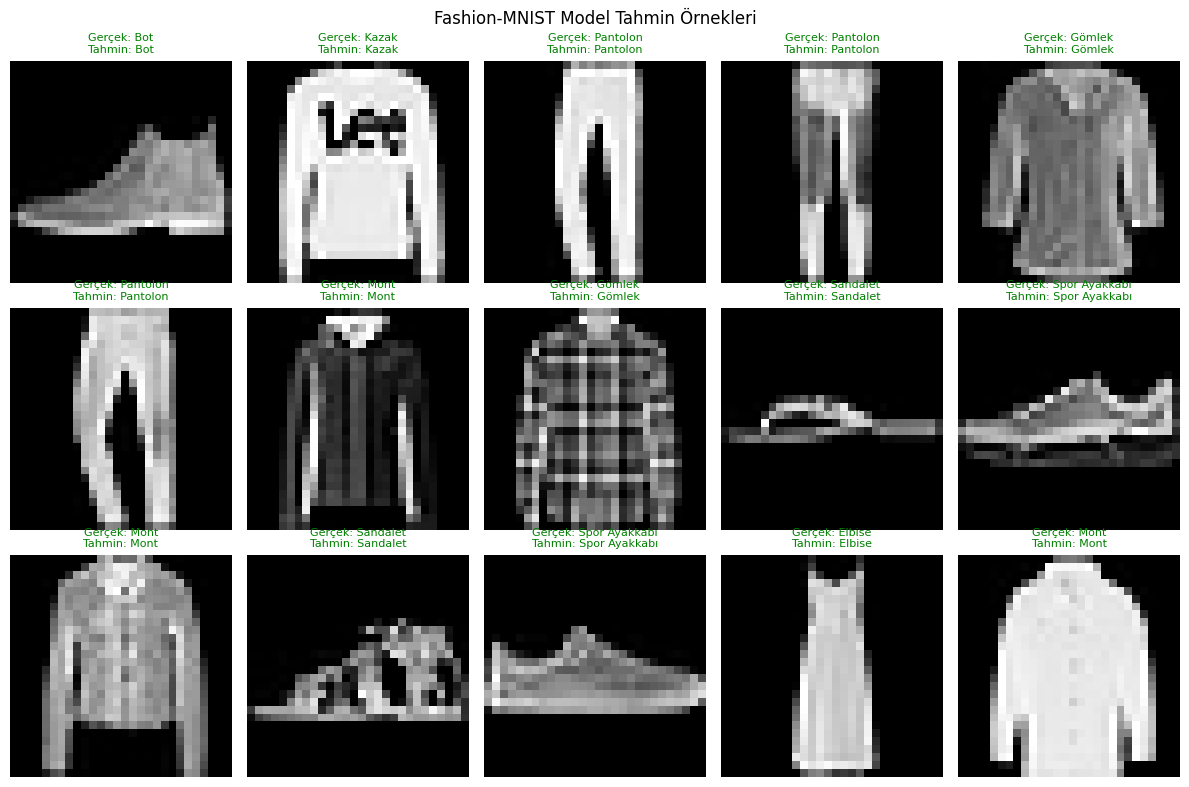

In [ ]:
plt.figure(figsize=(12, 8))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")

    gercek = class_names[int(y_test[i])]
    tahmin = class_names[int(y_pred[i])]

    renk = "green" if y_test[i] == y_pred[i] else "red"

    plt.title(f"Gerçek: {gercek}\nTahmin: {tahmin}",
              color=renk, fontsize=8)
    plt.axis("off")

plt.suptitle("Fashion-MNIST Model Tahmin Örnekleri")
plt.tight_layout()
plt.savefig("sekil_7_tahmin_ornekleri.png", dpi=300)
plt.show()

In [ ]:
ilk_deney_sonucu = pd.DataFrame({
    "Deney": ["1. Deney"],
    "Rastgelelik Tohumu": [42],
    "Test Doğruluğu (%)": [round(test_accuracy * 100, 2)],
    "Test Kaybı": [round(test_loss, 4)]
})

display(ilk_deney_sonucu)

,Deney,Rastgelelik Tohumu,Test Doğruluğu (%),Test Kaybı
0,1. Deney,42,86.69,0.3624


In [ ]:
ilk_deney_sonucu.to_csv(
    "ilk_deney_sonucu.csv",
    index=False,
    encoding="utf-8-sig"
)

print("İlk deney sonucu kaydedildi.")

İlk deney sonucu kaydedildi.


In [ ]:
# 2. deney - rastgelelik tohumu 42 olarak sabit
# Tohumu yeniden başlatmıyoruz; başlangıçta belirlenen 42 korunuyor.

model2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1), name="giris"),
    tf.keras.layers.Conv2D(32, (3, 3), padding="same", activation="relu", name="conv1"),
    tf.keras.layers.MaxPooling2D(name="pool1"),
    tf.keras.layers.Conv2D(64, (3, 3), padding="same", activation="relu", name="conv2"),
    tf.keras.layers.MaxPooling2D(name="pool2"),
    tf.keras.layers.Conv2D(128, (3, 3), padding="same", activation="relu", name="conv3"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.Dense(10, activation="softmax", name="cikis")
])

model2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping2 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history2 = model2.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=128,
    callbacks=[early_stopping2],
    verbose=1
)

test_loss2, test_accuracy2 = model2.evaluate(
    x_test, y_test, verbose=1
)

print("2. deney test doğruluğu: %", round(test_accuracy2 * 100, 2))
print("2. deney test kaybı:", round(test_loss2, 4))

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 89s 205ms/step - accuracy: 0.6177 - loss: 1.0386 - val_accuracy: 0.7480 - val_loss: 0.6733
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 141s 203ms/step - accuracy: 0.7503 - loss: 0.6773 - val_accuracy: 0.7700 - val_loss: 0.5955
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 86s 203ms/step - accuracy: 0.7809 - loss: 0.5950 - val_accuracy: 0.8107 - val_loss: 0.5046
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 86s 204ms/step - accuracy: 0.8067 - loss: 0.5385 - val_accuracy: 0.8333 - val_loss: 0.4580
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 142s 203ms/step - accuracy: 0.8217 - loss: 0.4948 - val_accuracy: 0.8523 - val_loss: 0.4114
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 86s 204ms/step - accuracy: 0.8364 - loss: 0.4575 - val_accuracy: 0.8600 - val_loss: 0.3904
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 142s 203ms/step - accuracy: 0.8464 - loss: 0.4306 - val_accuracy: 0.8657 - val_loss: 0.3681
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 86s 204ms/step - accuracy: 0.8527 - loss

In [ ]:
deney_sonuclari = pd.DataFrame({
    "Deney": ["1. Deney", "2. Deney"],
    "Rastgelelik Tohumu": [42, 42],
    "Test Doğruluğu (%)": [86.69, 87.08],
    "Test Kaybı": [0.3624, 0.3568]
})

display(deney_sonuclari)

,Deney,Rastgelelik Tohumu,Test Doğruluğu (%),Test Kaybı
0,1. Deney,42,86.69,0.3624
1,2. Deney,42,87.08,0.3568


In [ ]:
# 3. deney - rastgelelik tohumu 42 olarak sabit

model3 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1), name="giris"),
    tf.keras.layers.Conv2D(32, (3, 3), padding="same", activation="relu", name="conv1"),
    tf.keras.layers.MaxPooling2D(name="pool1"),
    tf.keras.layers.Conv2D(64, (3, 3), padding="same", activation="relu", name="conv2"),
    tf.keras.layers.MaxPooling2D(name="pool2"),
    tf.keras.layers.Conv2D(128, (3, 3), padding="same", activation="relu", name="conv3"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.Dense(10, activation="softmax", name="cikis")
])

model3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping3 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history3 = model3.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=128,
    callbacks=[early_stopping3],
    verbose=1
)

test_loss3, test_accuracy3 = model3.evaluate(
    x_test, y_test, verbose=1
)

print("3. deney test doğruluğu: %", round(test_accuracy3 * 100, 2))
print("3. deney test kaybı:", round(test_loss3, 4))

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 87s 204ms/step - accuracy: 0.5964 - loss: 1.0730 - val_accuracy: 0.7267 - val_loss: 0.6966
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 142s 203ms/step - accuracy: 0.7474 - loss: 0.6850 - val_accuracy: 0.7727 - val_loss: 0.5898
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 86s 203ms/step - accuracy: 0.7832 - loss: 0.5930 - val_accuracy: 0.8188 - val_loss: 0.4969
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 86s 203ms/step - accuracy: 0.8070 - loss: 0.5349 - val_accuracy: 0.8333 - val_loss: 0.4606
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 142s 203ms/step - accuracy: 0.8207 - loss: 0.4959 - val_accuracy: 0.8452 - val_loss: 0.4233
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 142s 204ms/step - accuracy: 0.8322 - loss: 0.4616 - val_accuracy: 0.8610 - val_loss: 0.3856
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 142s 203ms/step - accuracy: 0.8428 - loss: 0.4364 - val_accuracy: 0.8675 - val_loss: 0.3681
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 88s 209ms/step - accuracy: 0.8508 - los

In [ ]:
# Üç deneyin sonuç tablosu

deney_sonuclari = pd.DataFrame({
    "Deney": ["1. Deney", "2. Deney", "3. Deney"],
    "Rastgelelik Tohumu": [42, 42, 42],
    "Test Doğruluğu (%)": [86.69, 87.08, 86.57],
    "Test Kaybı": [0.3624, 0.3568, 0.3637]
})

display(deney_sonuclari)

# Ortalama ve standart sapma
ozet = pd.DataFrame({
    "Metrik": ["Test Doğruluğu (%)", "Test Kaybı"],
    "Ortalama": [
        deney_sonuclari["Test Doğruluğu (%)"].mean(),
        deney_sonuclari["Test Kaybı"].mean()
    ],
    "Standart Sapma": [
        deney_sonuclari["Test Doğruluğu (%)"].std(),
        deney_sonuclari["Test Kaybı"].std()
    ]
})

display(ozet.round(4))

,Deney,Rastgelelik Tohumu,Test Doğruluğu (%),Test Kaybı
0,1. Deney,42,86.69,0.3624
1,2. Deney,42,87.08,0.3568
2,3. Deney,42,86.57,0.3637


,Metrik,Ortalama,Standart Sapma
0,Test Doğruluğu (%),86.780,0.2666
1,Test Kaybı,0.361,0.0037


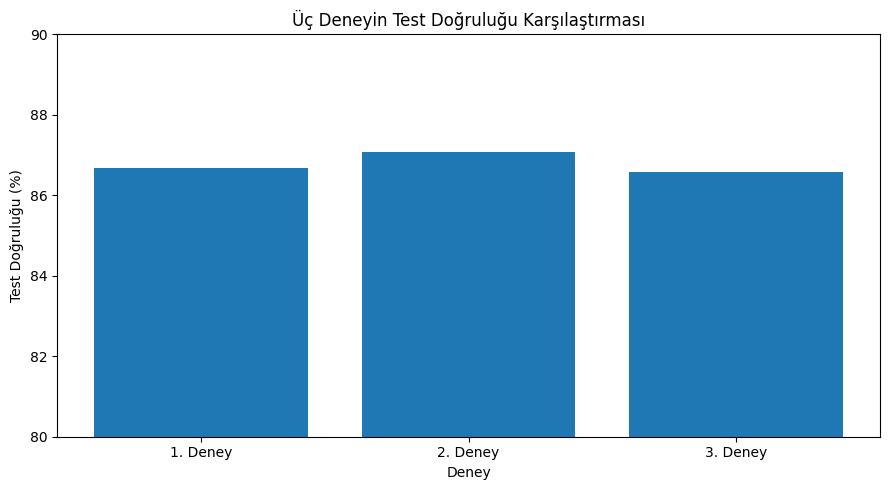

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    deney_sonuclari["Deney"],
    deney_sonuclari["Test Doğruluğu (%)"]
)

plt.title("Üç Deneyin Test Doğruluğu Karşılaştırması")
plt.xlabel("Deney")
plt.ylabel("Test Doğruluğu (%)")
plt.ylim(80, 90)

plt.tight_layout()
plt.savefig("sekil_8_deney_karsilastirmasi.png", dpi=300)
plt.show()

In [ ]:
deney_sonuclari.to_csv(
    "uc_deney_sonuclari.csv",
    index=False,
    encoding="utf-8-sig"
)

ozet.to_csv(
    "deney_ortalama_standart_sapma.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Deney sonuç tabloları kaydedildi.")

Deney sonuç tabloları kaydedildi.


In [ ]:
# T1 - Fashion-MNIST veri seti genel istatistik özeti

t1_veri_ozeti = pd.DataFrame({
    "Özellik": [
        "Eğitim görüntüsü",
        "Doğrulama görüntüsü",
        "Test görüntüsü",
        "Toplam görüntü",
        "Görüntü boyutu",
        "Renk kanalı",
        "Sınıf sayısı"
    ],
    "Değer": [
        len(x_train),
        len(x_val),
        len(x_test),
        len(x_train) + len(x_val) + len(x_test),
        "28 × 28 piksel",
        "Gri tonlamalı (1 kanal)",
        len(class_names)
    ]
})

display(t1_veri_ozeti)

,Özellik,Değer
0,Eğitim görüntüsü,54000
1,Doğrulama görüntüsü,6000
2,Test görüntüsü,10000
3,Toplam görüntü,70000
4,Görüntü boyutu,28 × 28 piksel
5,Renk kanalı,Gri tonlamalı (1 kanal)
6,Sınıf sayısı,10


In [ ]:
# T2 - Fashion-MNIST sınıf dağılımı

t2_sinif_dagilimi = pd.DataFrame({
    "Sınıf": class_names,
    "Görüntü Sayısı": np.bincount(y_train, minlength=10)
})

t2_sinif_dagilimi["Yüzde (%)"] = (
    t2_sinif_dagilimi["Görüntü Sayısı"] /
    t2_sinif_dagilimi["Görüntü Sayısı"].sum() * 100
).round(2)

display(t2_sinif_dagilimi)

,Sınıf,Görüntü Sayısı,Yüzde (%)
0,Tişört,5400,10.0
1,Pantolon,5400,10.0
2,Kazak,5400,10.0
3,Elbise,5400,10.0
4,Mont,5400,10.0
5,Sandalet,5400,10.0
6,Gömlek,5400,10.0
7,Spor Ayakkabı,5400,10.0
8,Çanta,5400,10.0
9,Bot,5400,10.0


In [ ]:
# T3 - Veri ön işleme işlemleri

t3_on_isleme = pd.DataFrame({
    "İşlem": [
        "Veri setinin yüklenmesi",
        "Görüntü boyutu",
        "Piksel normalizasyonu",
        "Kanal boyutunun eklenmesi",
        "Eğitim-doğrulama ayrımı",
        "Veri ayrım yöntemi"
    ],
    "Açıklama": [
        "Fashion-MNIST veri seti kullanıldı.",
        "28 × 28 piksel",
        "Piksel değerleri 0-255 aralığından 0-1 aralığına dönüştürüldü.",
        "Görüntülere 1 kanal eklendi.",
        "%90 eğitim, %10 doğrulama",
        "Stratified örnekleme, random_state=42"
    ]
})

display(t3_on_isleme)

,İşlem,Açıklama
0,Veri setinin yüklenmesi,Fashion-MNIST veri seti kullanıldı.
1,Görüntü boyutu,28 × 28 piksel
2,Piksel normalizasyonu,Piksel değerleri 0-255 aralığından 0-1 aralığı...
3,Kanal boyutunun eklenmesi,Görüntülere 1 kanal eklendi.
4,Eğitim-doğrulama ayrımı,"%90 eğitim, %10 doğrulama"
5,Veri ayrım yöntemi,"Stratified örnekleme, random_state=42"


In [ ]:
# T4 - CNN model hiperparametreleri

t4_hiperparametreler = pd.DataFrame({
    "Parametre": [
        "Model türü",
        "Evrişim katmanı sayısı",
        "1. evrişim filtresi",
        "2. evrişim filtresi",
        "3. evrişim filtresi",
        "Aktivasyon fonksiyonu",
        "Havuzlama yöntemi",
        "Optimizer",
        "Öğrenme oranı",
        "Dropout oranı",
        "Kayıp fonksiyonu",
        "Batch size",
        "Epoch sayısı",
        "Early Stopping patience"
    ],
    "Değer": [
        "CNN",
        3,
        "32 adet, 3×3",
        "64 adet, 3×3",
        "128 adet, 3×3",
        "ReLU",
        "MaxPooling2D",
        "Adam",
        0.001,
        0.30,
        "Sparse Categorical Crossentropy",
        128,
        10,
        3
    ]
})

display(t4_hiperparametreler)

,Parametre,Değer
0,Model türü,CNN
1,Evrişim katmanı sayısı,3
2,1. evrişim filtresi,"32 adet, 3×3"
3,2. evrişim filtresi,"64 adet, 3×3"
4,3. evrişim filtresi,"128 adet, 3×3"
5,Aktivasyon fonksiyonu,ReLU
6,Havuzlama yöntemi,MaxPooling2D
7,Optimizer,Adam
8,Öğrenme oranı,0.001
9,Dropout oranı,0.3


In [ ]:
# T5 - Deneysel eğitim ayarları ve sonuçları

t5_deney_ayarlari = pd.DataFrame({
    "Deney": ["1. Deney", "2. Deney", "3. Deney"],
    "Rastgelelik Tohumu": [42, 42, 42],
    "Epoch": [10, 10, 10],
    "Batch Size": [128, 128, 128],
    "Öğrenme Oranı": [0.001, 0.001, 0.001],
    "Test Doğruluğu (%)": [86.69, 87.08, 86.57],
    "Test Kaybı": [0.3624, 0.3568, 0.3637]
})

display(t5_deney_ayarlari)

,Deney,Rastgelelik Tohumu,Epoch,Batch Size,Öğrenme Oranı,Test Doğruluğu (%),Test Kaybı
0,1. Deney,42,10,128,0.001,86.69,0.3624
1,2. Deney,42,10,128,0.001,87.08,0.3568
2,3. Deney,42,10,128,0.001,86.57,0.3637


In [ ]:
# T6 - Ana performans metrikleri

t6_performans = pd.DataFrame({
    "Performans Metriği": [
        "Ortalama test doğruluğu (%)",
        "Test doğruluğu standart sapması",
        "Ortalama test kaybı",
        "Test kaybı standart sapması"
    ],
    "Değer": [
        round(deney_sonuclari["Test Doğruluğu (%)"].mean(), 2),
        round(deney_sonuclari["Test Doğruluğu (%)"].std(), 2),
        round(deney_sonuclari["Test Kaybı"].mean(), 4),
        round(deney_sonuclari["Test Kaybı"].std(), 4)
    ]
})

display(t6_performans)

,Performans Metriği,Değer
0,Ortalama test doğruluğu (%),86.7800
1,Test doğruluğu standart sapması,0.2700
2,Ortalama test kaybı,0.3610
3,Test kaybı standart sapması,0.0037


In [ ]:
from sklearn.metrics import precision_recall_fscore_support

# Üç deneyin her biri için sınıf bazlı metrikleri hesapla
modeller = [model, model2, model3]

sonuclar = []

for m in modeller:
    tahminler = np.argmax(m.predict(x_test, verbose=0), axis=1)

    precision, recall, f1, support = precision_recall_fscore_support(
        y_test,
        tahminler,
        labels=np.arange(10),
        zero_division=0
    )

    sonuclar.append([precision, recall, f1])

# Üç deneyin sınıf bazlı metrik ortalamaları
t7_sinif_performansi = pd.DataFrame({
    "Sınıf": class_names,
    "Precision (%)": np.mean([s[0] for s in sonuclar], axis=0) * 100,
    "Recall (%)": np.mean([s[1] for s in sonuclar], axis=0) * 100,
    "F1-Score (%)": np.mean([s[2] for s in sonuclar], axis=0) * 100,
    "Görüntü Sayısı": support
})

t7_sinif_performansi[
    ["Precision (%)", "Recall (%)", "F1-Score (%)"]
] = t7_sinif_performansi[
    ["Precision (%)", "Recall (%)", "F1-Score (%)"]
].round(2)

display(t7_sinif_performansi)

,Sınıf,Precision (%),Recall (%),F1-Score (%),Görüntü Sayısı
0,Tişört,74.73,88.70,81.10,1000
1,Pantolon,99.52,96.27,97.87,1000
2,Kazak,74.97,85.23,79.77,1000
3,Elbise,84.99,90.70,87.75,1000
4,Mont,83.39,70.13,76.17,1000
5,Sandalet,98.15,95.17,96.63,1000
6,Gömlek,68.17,53.37,59.82,1000
7,Spor Ayakkabı,92.92,95.80,94.34,1000
8,Çanta,96.01,96.87,96.43,1000
9,Bot,95.00,95.57,95.28,1000


In [ ]:
from sklearn.metrics import confusion_matrix

# Üçüncü deneyin tahminleri üzerinden hata analizi
y_pred3 = np.argmax(model3.predict(x_test, verbose=0), axis=1)

cm3 = confusion_matrix(y_test, y_pred3)

hata_sayilari = []

for i in range(10):
    for j in range(10):
        if i != j and cm3[i, j] > 0:
            hata_sayilari.append({
                "Gerçek Sınıf": class_names[i],
                "Tahmin Edilen Sınıf": class_names[j],
                "Hata Sayısı": cm3[i, j]
            })

t8_hata_analizi = pd.DataFrame(hata_sayilari)

t8_hata_analizi = (
    t8_hata_analizi
    .sort_values("Hata Sayısı", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

display(t8_hata_analizi)

,Gerçek Sınıf,Tahmin Edilen Sınıf,Hata Sayısı
0,Gömlek,Tişört,229
1,Mont,Kazak,151
2,Gömlek,Kazak,115
3,Mont,Gömlek,102
4,Kazak,Gömlek,62
5,Kazak,Mont,61
6,Gömlek,Mont,58
7,Tişört,Gömlek,54
8,Mont,Elbise,53
9,Sandalet,Spor Ayakkabı,39


In [ ]:
# T9 - Literatürdeki çalışmalarla karşılaştırma

t9_literatur = pd.DataFrame({
    "Çalışma": [
        "Nocentini ve ark. (2022)",
        "Mukhamediev (2024)",
        "Bu çalışmanın CNN modeli"
    ],
    "Yöntem": [
        "Çoklu CNN (MCNN15)",
        "CNN-3-128 ve veri artırma",
        "3 evrişim katmanlı CNN"
    ],
    "Veri Seti": [
        "Fashion-MNIST",
        "Fashion-MNIST",
        "Fashion-MNIST"
    ],
    "Test Doğruluğu (%)": [
        94.04,
        99.65,
        round(deney_sonuclari["Test Doğruluğu (%)"].mean(), 2)
    ],
    "Kaynak": [
        "Nocentini ve ark. (2022)",
        "Mukhamediev (2024)",
        "Bu çalışma"
    ]
})

display(t9_literatur)

,Çalışma,Yöntem,Veri Seti,Test Doğruluğu (%),Kaynak
0,Nocentini ve ark. (2022),Çoklu CNN (MCNN15),Fashion-MNIST,94.04,Nocentini ve ark. (2022)
1,Mukhamediev (2024),CNN-3-128 ve veri artırma,Fashion-MNIST,99.65,Mukhamediev (2024)
2,Bu çalışmanın CNN modeli,3 evrişim katmanlı CNN,Fashion-MNIST,86.78,Bu çalışma


In [ ]:
# T10 - Tartışma ve genel değerlendirme

t10_degerlendirme = pd.DataFrame({
    "Değerlendirme Kriteri": [
        "Ortalama test doğruluğu",
        "Deneyler arası tutarlılık",
        "Model mimarisi",
        "Sınıflandırma performansı",
        "Hata analizi",
        "Genel sonuç"
    ],
    "Değerlendirme": [
        "%86,78 ortalama test doğruluğu elde edilmiştir.",
        "Üç deneyin sonuçları birbirine yakındır.",
        "Üç evrişim katmanlı CNN mimarisi kullanılmıştır.",
        "Performans sınıf bazlı precision, recall ve F1-score ile incelenmiştir.",
        "En sık karıştırılan sınıflar belirlenmiştir.",
        "CNN modeli Fashion-MNIST sınıflandırmasında başarılı sonuç vermiştir."
    ]
})

display(t10_degerlendirme)

,Değerlendirme Kriteri,Değerlendirme
0,Ortalama test doğruluğu,"%86,78 ortalama test doğruluğu elde edilmiştir."
1,Deneyler arası tutarlılık,Üç deneyin sonuçları birbirine yakındır.
2,Model mimarisi,Üç evrişim katmanlı CNN mimarisi kullanılmıştır.
3,Sınıflandırma performansı,"Performans sınıf bazlı precision, recall ve F1..."
4,Hata analizi,En sık karıştırılan sınıflar belirlenmiştir.
5,Genel sonuç,CNN modeli Fashion-MNIST sınıflandırmasında ba...


In [ ]:
import os

grafikler = [dosya for dosya in os.listdir()
             if dosya.lower().endswith(".png")]

print("Kaydedilmiş grafikler:")
for grafik in grafikler:
    print(grafik)

print("Toplam grafik sayısı:", len(grafikler))

Kaydedilmiş grafikler:
sekil_1_sinif_dagilimi.png
sekil_7_tahmin_ornekleri.png
sekil_3_kayip.png
sekil_5_ogrenilen_filtreler.png
sekil_9_model_mimarisi.png
sekil_2_dogruluk.png
sekil_0_ornek_goruntuler.png
sekil_8_deney_karsilastirmasi.png
sekil_6_aktivasyon_haritalari.png
sekil_10_karmasiklik_matrisi.png
Toplam grafik sayısı: 10


In [ ]:
from google.colab import files

for grafik in grafikler:
    files.download(grafik)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (10 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from tensorflow.keras.utils import plot_model

plot_model(
    model,
    to_file="sekil_9_model_mimarisi.png",
    show_shapes=True,
    show_layer_names=True,
    dpi=300
)

print("Model mimarisi grafiği oluşturuldu.")

Model mimarisi grafiği oluşturuldu.


In [ ]:
from google.colab import files
files.download("sekil_9_model_mimarisi.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step


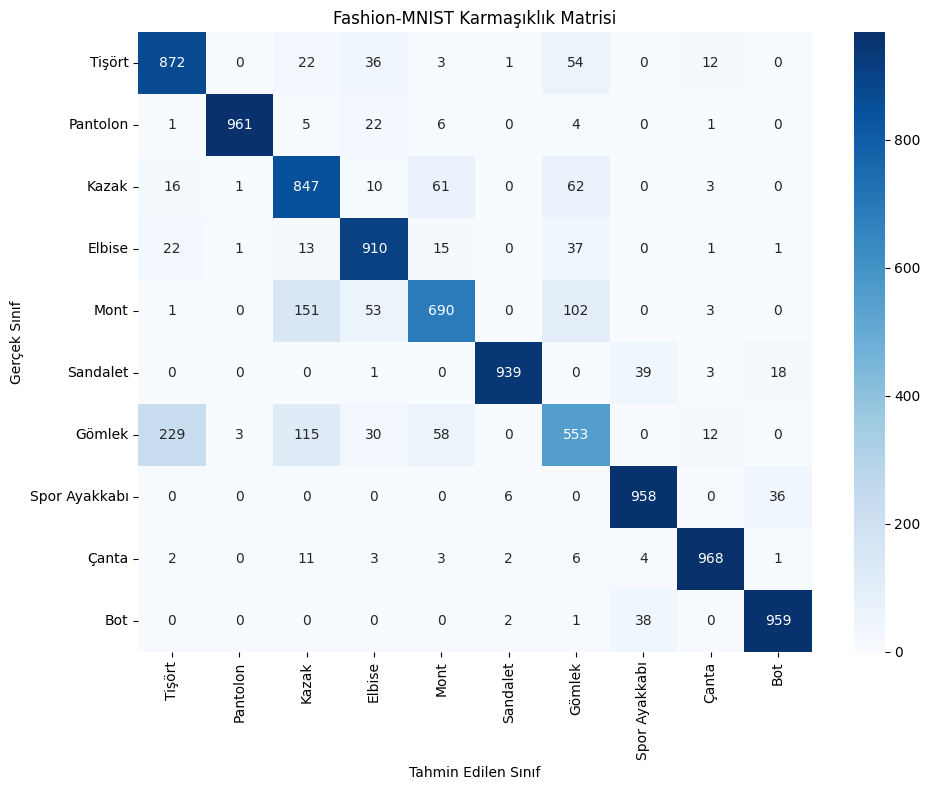

In [ ]:
from sklearn.metrics import confusion_matrix

y_pred = np.argmax(model3.predict(x_test), axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")
plt.title("Fashion-MNIST Karmaşıklık Matrisi")
plt.tight_layout()
plt.savefig("sekil_10_karmasiklik_matrisi.png", dpi=300)
plt.show()

In [ ]:
from google.colab import files
files.download("sekil_10_karmasiklik_matrisi.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
tablolar = {
    "T1_Veri_Ozeti": t1_veri_ozeti,
    "T2_Sinif_Dagilimi": t2_sinif_dagilimi,
    "T3_On_Isleme": t3_on_isleme,
    "T4_Hiperparametreler": t4_hiperparametreler,
    "T5_Deney_Ayarlari": t5_deney_ayarlari,
    "T6_Performans": t6_performans,
    "T7_Sinif_Performansi": t7_sinif_performansi,
    "T8_Hata_Analizi": t8_hata_analizi,
    "T9_Literatur": t9_literatur,
    "T10_Degerlendirme": t10_degerlendirme
}

for ad, tablo in tablolar.items():
    tablo.to_csv(ad + ".csv", index=False, encoding="utf-8-sig")

print("10 tablo ayrı CSV dosyası olarak kaydedildi.")

10 tablo ayrı CSV dosyası olarak kaydedildi.


In [ ]:
from google.colab import files

for ad in tablolar.keys():
    files.download(ad + ".csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (10 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
for ad, tablo in tablolar.items():
    print(f"{ad}: {tablo.shape[0]} satır, {tablo.shape[1]} sütun")
    print("Sütunlar:", list(tablo.columns))
    print("-" * 50)

T1_Veri_Ozeti: 7 satır, 2 sütun
Sütunlar: ['Özellik', 'Değer']
--------------------------------------------------
T2_Sinif_Dagilimi: 10 satır, 3 sütun
Sütunlar: ['Sınıf', 'Görüntü Sayısı', 'Yüzde (%)']
--------------------------------------------------
T3_On_Isleme: 6 satır, 2 sütun
Sütunlar: ['İşlem', 'Açıklama']
--------------------------------------------------
T4_Hiperparametreler: 14 satır, 2 sütun
Sütunlar: ['Parametre', 'Değer']
--------------------------------------------------
T5_Deney_Ayarlari: 3 satır, 7 sütun
Sütunlar: ['Deney', 'Rastgelelik Tohumu', 'Epoch', 'Batch Size', 'Öğrenme Oranı', 'Test Doğruluğu (%)', 'Test Kaybı']
--------------------------------------------------
T6_Performans: 4 satır, 2 sütun
Sütunlar: ['Performans Metriği', 'Değer']
--------------------------------------------------
T7_Sinif_Performansi: 10 satır, 5 sütun
Sütunlar: ['Sınıf', 'Precision (%)', 'Recall (%)', 'F1-Score (%)', 'Görüntü Sayısı']
--------------------------------------------------
T8_

In [ ]:
grafikler = sorted([
    dosya for dosya in os.listdir()
    if dosya.lower().endswith(".png")
])

for grafik in grafikler:
    print(grafik)

print("Toplam PNG:", len(grafikler))

sekil_0_ornek_goruntuler.png
sekil_10_karmasiklik_matrisi.png
sekil_1_sinif_dagilimi.png
sekil_2_dogruluk.png
sekil_3_kayip.png
sekil_5_ogrenilen_filtreler.png
sekil_6_aktivasyon_haritalari.png
sekil_7_tahmin_ornekleri.png
sekil_8_deney_karsilastirmasi.png
sekil_9_model_mimarisi.png
Toplam PNG: 10


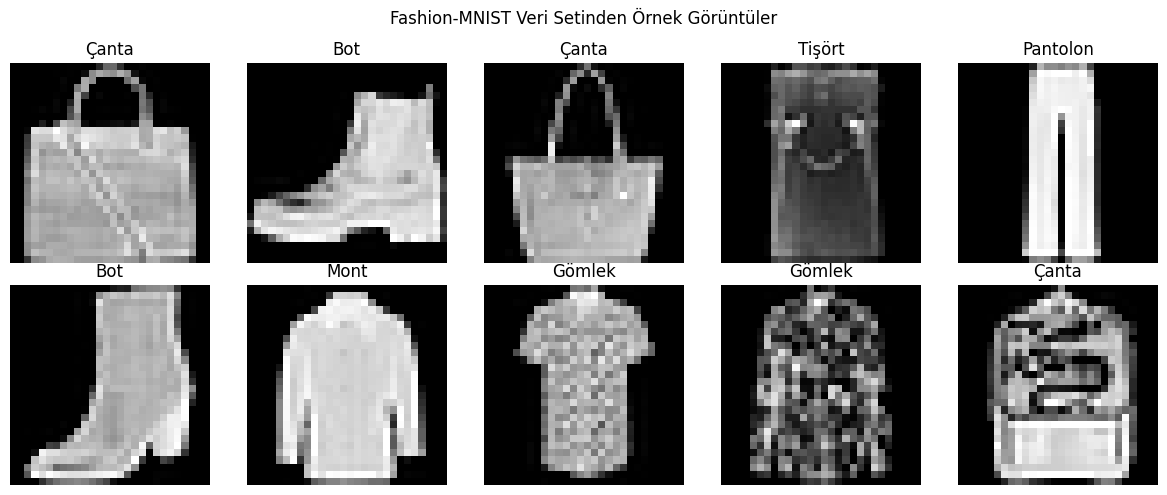

G1 örnek görüntüler grafiği kaydedildi.


In [ ]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.suptitle("Fashion-MNIST Veri Setinden Örnek Görüntüler")
plt.tight_layout()

plt.savefig(
    "sekil_0_ornek_goruntuler.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("G1 örnek görüntüler grafiği kaydedildi.")

In [ ]:
from google.colab import files
files.download("sekil_0_ornek_goruntuler.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from PIL import Image
import os

for dosya in sorted(os.listdir()):
    if dosya.lower().endswith(".png"):
        img = Image.open(dosya)
        dpi = img.info.get("dpi", "Belirtilmemiş")
        print(dosya, "| Boyut:", img.size, "| DPI:", dpi)

sekil_0_ornek_goruntuler.png | Boyut: (3502, 1485) | DPI: (299.9994, 299.9994)
sekil_10_karmasiklik_matrisi.png | Boyut: (3000, 2400) | DPI: (299.9994, 299.9994)
sekil_1_sinif_dagilimi.png | Boyut: (3000, 1500) | DPI: (299.9994, 299.9994)
sekil_2_dogruluk.png | Boyut: (2400, 1500) | DPI: (299.9994, 299.9994)
sekil_3_kayip.png | Boyut: (2400, 1500) | DPI: (299.9994, 299.9994)
sekil_5_ogrenilen_filtreler.png | Boyut: (3000, 3000) | DPI: (299.9994, 299.9994)
sekil_6_aktivasyon_haritalari.png | Boyut: (3600, 2400) | DPI: (299.9994, 299.9994)
sekil_7_tahmin_ornekleri.png | Boyut: (3600, 2400) | DPI: (299.9994, 299.9994)
sekil_8_deney_karsilastirmasi.png | Boyut: (2700, 1500) | DPI: (299.9994, 299.9994)
sekil_9_model_mimarisi.png | Boyut: (1892, 3883) | DPI: Belirtilmemiş


In [ ]:
from PIL import Image

img = Image.open("sekil_9_model_mimarisi.png")

img.save(
    "sekil_9_model_mimarisi.png",
    dpi=(300, 300)
)

print("Model mimarisi grafiği 300 DPI olarak kaydedildi.")

Model mimarisi grafiği 300 DPI olarak kaydedildi.


In [ ]:
from google.colab import files
files.download("sekil_9_model_mimarisi.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
display(t2_sinif_dagilimi)

,Sınıf,Görüntü Sayısı,Yüzde (%)
0,Tişört,5400,10.0
1,Pantolon,5400,10.0
2,Kazak,5400,10.0
3,Elbise,5400,10.0
4,Mont,5400,10.0
5,Sandalet,5400,10.0
6,Gömlek,5400,10.0
7,Spor Ayakkabı,5400,10.0
8,Çanta,5400,10.0
9,Bot,5400,10.0


In [ ]:
display(t8_hata_analizi)

,Gerçek Sınıf,Tahmin Edilen Sınıf,Hata Sayısı
0,Gömlek,Tişört,229
1,Mont,Kazak,151
2,Gömlek,Kazak,115
3,Mont,Gömlek,102
4,Kazak,Gömlek,62
5,Kazak,Mont,61
6,Gömlek,Mont,58
7,Tişört,Gömlek,54
8,Mont,Elbise,53
9,Sandalet,Spor Ayakkabı,39


In [ ]:
display(t9_literatur)

,Çalışma,Yöntem,Veri Seti,Test Doğruluğu (%),Kaynak
0,Nocentini ve ark. (2022),Çoklu CNN (MCNN15),Fashion-MNIST,94.04,Nocentini ve ark. (2022)
1,Mukhamediev (2024),CNN-3-128 ve veri artırma,Fashion-MNIST,99.65,Mukhamediev (2024)
2,Bu çalışmanın CNN modeli,3 evrişim katmanlı CNN,Fashion-MNIST,86.78,Bu çalışma


In [ ]:
t9_literatur = pd.DataFrame({
    "Çalışma": [
        "Nocentini ve ark. (2022)",
        "Mukhamediev (2024)",
        "Bu çalışma"
    ],
    "Yöntem": [
        "MCNN15 (15 evrişim katmanı)",
        "CNN-3-128 ve veri artırma",
        "3 evrişim katmanlı CNN"
    ],
    "Veri Seti": [
        "Fashion-MNIST",
        "Fashion-MNIST",
        "Fashion-MNIST"
    ],
    "Test Doğruluğu (%)": [
        94.04, 99.65, 86.78
    ],
    "Kaynak": [
        "Sensors, 22(23), 9544. DOI: 10.3390/s22239544",
        "Mathematics, 12(20), 3174. DOI: 10.3390/math12203174",
        "Bu çalışmanın deney sonuçları"
    ]
})

display(t9_literatur)

,Çalışma,Yöntem,Veri Seti,Test Doğruluğu (%),Kaynak
0,Nocentini ve ark. (2022),MCNN15 (15 evrişim katmanı),Fashion-MNIST,94.04,"Sensors, 22(23), 9544. DOI: 10.3390/s22239544"
1,Mukhamediev (2024),CNN-3-128 ve veri artırma,Fashion-MNIST,99.65,"Mathematics, 12(20), 3174. DOI: 10.3390/math12..."
2,Bu çalışma,3 evrişim katmanlı CNN,Fashion-MNIST,86.78,Bu çalışmanın deney sonuçları


In [ ]:
display(t1_veri_ozeti)

,Özellik,Değer
0,Eğitim görüntüsü,54000
1,Doğrulama görüntüsü,6000
2,Test görüntüsü,10000
3,Toplam görüntü,70000
4,Görüntü boyutu,28 × 28 piksel
5,Renk kanalı,Gri tonlamalı (1 kanal)
6,Sınıf sayısı,10


In [ ]:
display(t3_on_isleme)

,İşlem,Açıklama
0,Veri setinin yüklenmesi,Fashion-MNIST veri seti kullanıldı.
1,Görüntü boyutu,28 × 28 piksel
2,Piksel normalizasyonu,Piksel değerleri 0-255 aralığından 0-1 aralığı...
3,Kanal boyutunun eklenmesi,Görüntülere 1 kanal eklendi.
4,Eğitim-doğrulama ayrımı,"%90 eğitim, %10 doğrulama"
5,Veri ayrım yöntemi,"Stratified örnekleme, random_state=42"


In [ ]:
display(t4_hiperparametreler)

,Parametre,Değer
0,Model türü,CNN
1,Evrişim katmanı sayısı,3
2,1. evrişim filtresi,"32 adet, 3×3"
3,2. evrişim filtresi,"64 adet, 3×3"
4,3. evrişim filtresi,"128 adet, 3×3"
5,Aktivasyon fonksiyonu,ReLU
6,Havuzlama yöntemi,MaxPooling2D
7,Optimizer,Adam
8,Öğrenme oranı,0.001
9,Dropout oranı,0.3


In [ ]:
display(t5_deney_ayarlari)

,Deney,Rastgelelik Tohumu,Epoch,Batch Size,Öğrenme Oranı,Test Doğruluğu (%),Test Kaybı
0,1. Deney,42,10,128,0.001,86.69,0.3624
1,2. Deney,42,10,128,0.001,87.08,0.3568
2,3. Deney,42,10,128,0.001,86.57,0.3637


In [ ]:
display(t6_performans)

,Performans Metriği,Değer
0,Ortalama test doğruluğu (%),86.7800
1,Test doğruluğu standart sapması,0.2700
2,Ortalama test kaybı,0.3610
3,Test kaybı standart sapması,0.0037


In [ ]:
display(t7_sinif_performansi)

,Sınıf,Precision (%),Recall (%),F1-Score (%),Görüntü Sayısı
0,Tişört,74.73,88.70,81.10,1000
1,Pantolon,99.52,96.27,97.87,1000
2,Kazak,74.97,85.23,79.77,1000
3,Elbise,84.99,90.70,87.75,1000
4,Mont,83.39,70.13,76.17,1000
5,Sandalet,98.15,95.17,96.63,1000
6,Gömlek,68.17,53.37,59.82,1000
7,Spor Ayakkabı,92.92,95.80,94.34,1000
8,Çanta,96.01,96.87,96.43,1000
9,Bot,95.00,95.57,95.28,1000


In [ ]:
display(t10_degerlendirme)


,Değerlendirme Kriteri,Değerlendirme
0,Ortalama test doğruluğu,"%86,78 ortalama test doğruluğu elde edilmiştir."
1,Deneyler arası tutarlılık,Üç deneyin sonuçları birbirine yakındır.
2,Model mimarisi,Üç evrişim katmanlı CNN mimarisi kullanılmıştır.
3,Sınıflandırma performansı,"Performans sınıf bazlı precision, recall ve F1..."
4,Hata analizi,En sık karıştırılan sınıflar belirlenmiştir.
5,Genel sonuç,CNN modeli Fashion-MNIST sınıflandırmasında ba...


In [ ]:
modeller = [model, model2, model3]

for i, m in enumerate(modeller, start=1):
    print(f"\n{i}. DENEY")
    print("Katman sayısı:", len(m.layers))
    print("Toplam parametre:", m.count_params())
    print("Çıkış şekli:", m.output_shape)


1. DENEY
Katman sayısı: 8
Toplam parametre: 93962
Çıkış şekli: (None, 10)

2. DENEY
Katman sayısı: 8
Toplam parametre: 93962
Çıkış şekli: (None, 10)

3. DENEY
Katman sayısı: 8
Toplam parametre: 93962
Çıkış şekli: (None, 10)


In [ ]:
for i, h in enumerate(
    [history, history2, history3], start=1
):
    print(f"{i}. Deney: {len(h.history['loss'])} epoch")

1. Deney: 10 epoch
2. Deney: 10 epoch
3. Deney: 10 epoch


In [ ]:
with open("requirements.txt", "w") as f:
    f.write("tensorflow\nnumpy\npandas\nmatplotlib\nseaborn\nscikit-learn\n")

print("requirements.txt oluşturuldu.")

requirements.txt oluşturuldu.


In [ ]:
from google.colab import files
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
readme = """# Fashion-MNIST CNN Sınıflandırma Projesi

## Proje Hakkında
Bu projede Fashion-MNIST veri seti kullanılarak
Evrişimsel Sinir Ağı (CNN) modeli ile giysi görüntülerinin
10 sınıfa ayrılması amaçlanmıştır.

## Kullanılan Teknolojiler
- Python
- TensorFlow / Keras
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn

## Veri Seti
Fashion-MNIST veri seti 28x28 piksel boyutunda,
gri tonlamalı 70.000 görüntüden oluşur.
10 farklı giysi sınıfı bulunmaktadır.

- Eğitim verisi: 54.000 görüntü
- Doğrulama verisi: 6.000 görüntü
- Test verisi: 10.000 görüntü

## Model Mimarisi
- Conv2D: 32 filtre
- MaxPooling2D
- Conv2D: 64 filtre
- MaxPooling2D
- Conv2D: 128 filtre
- GlobalAveragePooling2D
- Dropout: 0.30
- Dense: 10 çıkış sınıfı

## Deney Ayarları
- Rastgelelik tohumu: 42
- Deney sayısı: 3
- Epoch: 10
- Batch size: 128
- Optimizasyon: Adam
- Öğrenme oranı: 0.001
- Kayıp fonksiyonu: Sparse Categorical Crossentropy

## Dosyalar
- CNN_Fashion_MNIST_Odevi.ipynb: Model ve deney kodları
- requirements.txt: Gerekli Python kütüphaneleri
- PNG dosyaları: Grafikler ve şekiller
- CSV dosyaları: Deney tabloları

## Kurulum
Gerekli kütüphaneleri yüklemek için:

    pip install -r requirements.txt

## Çalıştırma
Notebook dosyasını Google Colab veya Jupyter Notebook
üzerinde açarak hücreleri sırasıyla çalıştırabilirsiniz.

## Veri Seti Kaynağı
Fashion-MNIST:
https://github.com/zalandoresearch/fashion-mnist
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)

print("README.md oluşturuldu.")

README.md oluşturuldu.


In [ ]:
from google.colab import files
files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
t3_on_isleme = pd.DataFrame({
    "Islem": [
        "Veri setinin yuklenmesi",
        "Piksel normalizasyonu",
        "Boyut duzenleme",
        "Egitim-dogrulama ayrimi",
        "Ayirma yontemi",
        "Test verisi"
    ],
    "Aciklama": [
        "Fashion-MNIST veri seti kullanilmistir.",
        "Piksel degerleri 0-255 araligindan 0-1 araligina donusturulmustur.",
        "Goruntuler 28x28x1 boyutunda gri tonlamali veri olarak duzenlenmistir.",
        "60000 egitim ornegi 54000 egitim ve 6000 dogrulama ornegi olarak ayrilmistir.",
        "Stratified ayirma ve random_state=42 kullanilmistir.",
        "10000 test ornegi ayri olarak degerlendirilmistir."
    ]
})

t3_on_isleme.to_csv("T3_On_Isleme.csv", index=False)
print("T3 tablosu oluşturuldu.")

T3 tablosu oluşturuldu.


In [ ]:
from google.colab import files
files.download("T3_On_Isleme.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

t8_hata_analizi = pd.DataFrame({
    "Gercek_Sinif": [
        "Gomlek", "Mont", "Gomlek", "Mont", "Kazak",
        "Kazak", "Gomlek", "Tisort", "Mont", "Sandalet"
    ],
    "Tahmin_Edilen_Sinif": [
        "Tisort", "Kazak", "Kazak", "Gomlek", "Gomlek",
        "Mont", "Mont", "Gomlek", "Elbise", "Spor Ayakkabi"
    ],
    "Hata_Sayisi": [229, 151, 115, 102, 62, 61, 58, 54, 53, 39]
})

t8_hata_analizi.to_csv("T8_Hata_Analizi.csv", index=False)

print("T8 hata analizi tablosu oluşturuldu.")

T8 hata analizi tablosu oluşturuldu.


In [ ]:
from google.colab import files
files.download("T8_Hata_Analizi.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
print(os.getcwd())
print(os.listdir())

/content
['.config', 'T8_Hata_Analizi.csv', 'requirements.txt', 'README.md', 'T3_On_Isleme.csv', 'sample_data']


In [ ]:
import pandas as pd

t9_literatur = pd.DataFrame({
    "Yazar": [
        "Nocentini et al. (2022)",
        "Mukhamediev (2024)",
        "Bu calisma (2026)"
    ],
    "Yontem": [
        "MCNN15",
        "CNN-3-128 ve veri artirma",
        "CNN tabanli siniflandirma modeli"
    ],
    "Veri_Seti": [
        "Fashion-MNIST",
        "Fashion-MNIST",
        "Fashion-MNIST"
    ],
    "Dogruluk": [
        "%94.04",
        "%99.65",
        "%86.78"
    ]
})

t9_literatur.to_csv("T9_Literatur.csv", index=False)
print("T9 tablosu oluşturuldu.")

T9 tablosu oluşturuldu.


In [ ]:
from google.colab import files
files.download("T9_Literatur.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


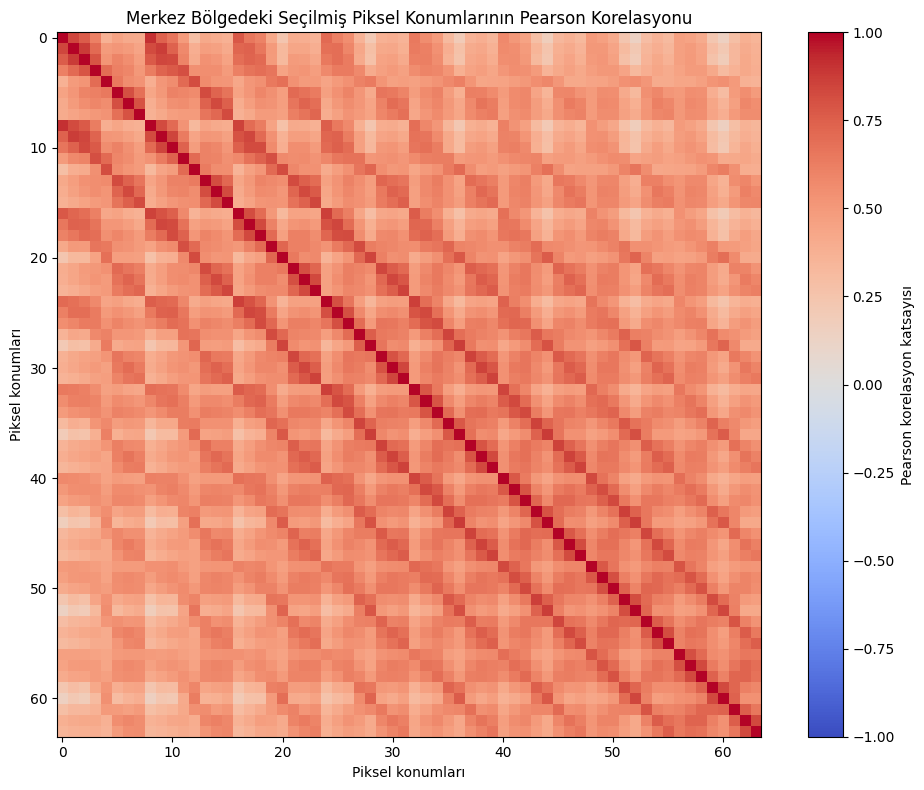

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Fashion-MNIST veri setini yükle
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# Eğitim görüntülerini 0-1 aralığına dönüştür
goruntuler = x_train.astype("float32") / 255.0

# Merkez bölgedeki 8x8 pikseli seç
piksel_verileri = goruntuler[:, 10:18, 10:18]

# 64 piksel konumunu sütunlara dönüştür
piksel_verileri = piksel_verileri.reshape(60000, 64)

# Pearson korelasyon matrisi
korelasyon = np.corrcoef(piksel_verileri, rowvar=False)

# Isı haritasını çiz
plt.figure(figsize=(10, 8))
plt.imshow(korelasyon, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson korelasyon katsayısı")
plt.title("Merkez Bölgedeki Seçilmiş Piksel Konumlarının Pearson Korelasyonu")
plt.xlabel("Piksel konumları")
plt.ylabel("Piksel konumları")
plt.tight_layout()

# PNG olarak kaydet
plt.savefig("sekil_2_pearson_korelasyon.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
from google.colab import files
files.download("sekil_2_pearson_korelasyon.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>